# Interview Question 1: (Precision, Recall and F1 / Classification)

A hospital deploys a model that screens chest X-rays for a serious but treatable lung disease. About 2% of patients have it. On 10,000 test patients the model produces:

* 150 true positives
* 50 false negatives
* 450 false positives
* 9,350 true negatives

1. Compute precision, recall, F1 and accuracy. Show your working.
2. A radiologist says “we must not miss sick patients”, while the hospital administrator says “we can’t afford to send hundreds of healthy people for expensive follow-up scans”. Which metric does each person care about, and which way would you move the threshold for each?
3. A colleague proposes a second model with precision 0.60 and recall 0.30 and says it’s “better” because its precision is higher. How would you compare the two models fairly, and when would you use F2 instead of F1?

## My Answer

$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}} = \frac{150}{150 + 450} = \frac{150}{600} = 0.25$$

$$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}} = \frac{150}{150 + 50} = \frac{150}{200} = 0.75$$

$$\text{F1} = \frac{2PR}{P + R} = \frac{2 \times 0.25 \times 0.75}{0.25 + 0.75} = 0.375$$

$$\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}} = \frac{150 + 9350}{(150 + 9350) + (450 + 50)} = 0.95$$

I have attached the working and the calculations in the image. Regarding the second question, the radiologist doesn't want to miss sick patients, so he cares more about recall and he wants the false negative cases to be as low as possible. The hospital administrator cares about precision. He wants it to be high and wants false positive as low as possible. Otherwise, those people who don't have disease will also come up for testing and increase the cost for the hospital. Regarding the third question, the colleague who came up with new precision and recall, the new F2 score is 0.4, whereas the old F score is 0.4 and the old F1 score was 0.375. So there's a slight increase in the F1 score. I don't know how to compare this model, but based on the F1 score, the new precision and recall looks better. But it's the old recall is better as it doesn't exclude the old patients. So I need help in understanding how to compare these two models with respect to the doctor and the hospital administrator.

**Evaluation of Question 4**

**Part 1: fully correct.** Precision 150/600 = 0.25, recall 150/200 = 0.75, F1 = 0.375, accuracy 9500/10000 = 0.95. Your working is clean. Note that 95% accuracy looks great while precision is only 0.25, which is the whole point of the question.

**Part 2: right metrics, but you missed the threshold direction and the conflict.**
- Radiologist wants recall, so you **lower** the threshold: more flagged, fewer FN, more FP.
- Administrator wants precision, so you **raise** the threshold: fewer flagged, fewer FP, more FN.
- They pull in opposite directions, so one threshold can't satisfy both. The real answer is to price the errors, or use two stages (cheap screen at high recall, then a second check before the expensive scan).

**Part 3: this is where the gap is.**
- Small correction: the new model's 0.4 is its **F1** (2 x 0.6 x 0.3 / 0.9). F2 is different.
- F1 (0.4 vs 0.375) is a near tie and weights precision and recall equally, which doesn't match this hospital.
- **F2 = 5PR / (4P + R)** weights recall twice as heavily: old model **0.54**, new model **0.33**. The ranking flips.
- Best way to compare is to turn the rates into patient counts per 10,000:

| | Old | New |
|---|---|---|
| Sick patients caught (TP) | 150 | 60 |
| Sick patients missed (FN) | 50 | 140 |
| Healthy sent for scan (FP) | 450 | 40 |

The new model removes 410 unnecessary scans but misses 90 more sick patients. It wins only if one missed patient costs less than about 4.6 follow-up scans (410 / 90). For a serious but treatable disease a miss costs far more than that, so the old model is better here. Your instinct that "the old recall is better" was right, and this makes it quantitative.

**Rule to remember:** compare models by `cost_FN x FN + cost_FP x FP`, or at a fixed recall target (say recall at least 0.9, then compare precision). Also check whether the two models are really just one model at two thresholds by comparing the full precision-recall curve. Use F2 when a miss is costlier than a false alarm (screening, fraud, safety), and F0.5 when false alarms are costlier (spam filters, auto-blocking).

**Production example:** mammography and cancer screening deliberately run at high recall and low precision (most flags are false alarms), then rely on a second-stage biopsy or specialist review to restore precision.

The two thresholds behave like your old and new models: one catches more sick patients, the other sends fewer healthy ones, and the cost line shows which wins once you price the errors.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, precision_recall_curve,
                             precision_score, recall_score, f1_score,
                             fbeta_score, ConfusionMatrixDisplay)

Low threshold (recall-focused) (thr=0.05): TP=46 FN=75 FP=376 TN=4503 | P=0.11 R=0.38 F1=0.17 F2=0.25 cost=1126
High threshold (precision-focused) (thr=0.4): TP=6 FN=115 FP=0 TN=4879 | P=1.00 R=0.05 F1=0.09 F2=0.06 cost=1150


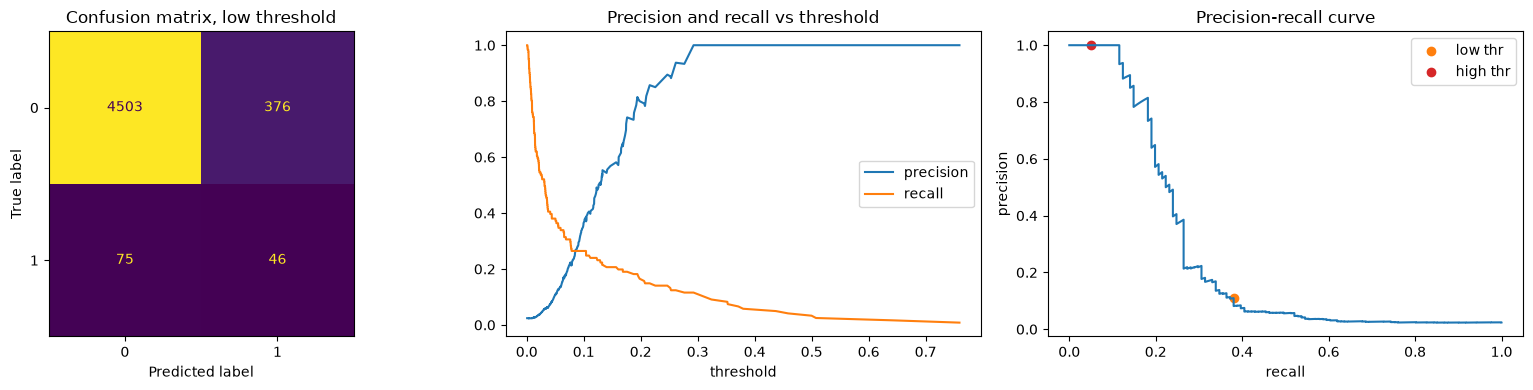

In [2]:

# 2% prevalence, like the hospital scenario
X, y = make_classification(n_samples=10_000, n_features=10, n_informative=4,
                           weights=[0.98], flip_y=0.01, class_sep=1.0,
                           random_state=0)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.5, stratify=y, random_state=0)
p = LogisticRegression(max_iter=1000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]

C_FN, C_FP = 10, 1   # assumed: a missed patient costs 10x a needless scan

def report(name, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    print(f"{name} (thr={t}): TP={tp} FN={fn} FP={fp} TN={tn} | "
          f"P={precision_score(yte, pred):.2f} R={recall_score(yte, pred):.2f} "
          f"F1={f1_score(yte, pred):.2f} F2={fbeta_score(yte, pred, beta=2):.2f} "
          f"cost={C_FN * fn + C_FP * fp}")
    return pred

pred_a = report("Low threshold (recall-focused)", 0.05)
pred_b = report("High threshold (precision-focused)", 0.40)

prec, rec, thr = precision_recall_curve(yte, p)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(yte, pred_a, ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix, low threshold")
ax[1].plot(thr, prec[:-1], label="precision")
ax[1].plot(thr, rec[:-1], label="recall")
ax[1].set_xlabel("threshold"); ax[1].set_title("Precision and recall vs threshold")
ax[1].legend()
ax[2].plot(rec, prec)
ax[2].scatter([recall_score(yte, pred_a)], [precision_score(yte, pred_a)], c="C1", label="low thr")
ax[2].scatter([recall_score(yte, pred_b)], [precision_score(yte, pred_b)], c="C3", label="high thr")
ax[2].set_xlabel("recall"); ax[2].set_ylabel("precision")
ax[2].set_title("Precision-recall curve"); ax[2].legend()
plt.tight_layout(); 
plt.show()